# EEG Modeling — Seizure Detection Baseline (CHB-MIT)

This notebook implements the **baseline modeling stage** for the CHB-MIT seizure-detection target.
Preprocessing is complete, validated, and frozen (`EEG_preprocessing.ipynb`); this notebook only
consumes the already-generated processed feature artifact and does not touch raw EDF data.

## 1. Baseline objective

This is a **sanity-check baseline**, not a model-selection or model-comparison study. Its narrow
purpose is to answer one question:

> Do the engineered EEG features contain any detectable signal associated with the annotated
> seizure epochs?

Setup:

- `X` consists of engineered CHB epoch-level EEG features (spectral power, ratios, entropy, etc.).
- `y = y_seizure`, a binary current-epoch seizure-annotation-overlap target.
- The classes are severely imbalanced: 3 positive epochs out of 360 (≈0.83%).
- **Only one seizure event exists** in the available data (recording `chb_s01_r03`), and the 3
  positive epochs are temporally adjacent segments of that single event.

**The baseline evaluates feature separability, not clinically valid seizure generalization.**
With a single seizure event, no split of the data can produce an independent held-out seizure to
estimate true generalization against. This limitation is treated as a first-class scientific
finding throughout the notebook, not an implementation detail to work around.

## 2. Imports and configuration

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    balanced_accuracy_score,
    accuracy_score,
    confusion_matrix,
    precision_recall_curve,
)

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd()
FEATURES_PATH = PROJECT_ROOT / "outputs" / "features_chb.parquet"

OUT_DIR = PROJECT_ROOT / "outputs" / "modeling" / "baseline"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Features source:", FEATURES_PATH)
print("Output directory:", OUT_DIR)

Features source: /home/evgenija/projects/EEG_timeseries_project/outputs/features_chb.parquet
Output directory: /home/evgenija/projects/EEG_timeseries_project/outputs/modeling/baseline


## 3. Load processed CHB features

Loading the existing preprocessing artifact only. No raw EDF data is read and no epoching or
feature engineering is repeated here.

In [2]:
df = pd.read_parquet(FEATURES_PATH)

# --- Structural assertions against the frozen preprocessing contract ---
assert len(df) == 360, f"Expected 360 rows, got {len(df)}"
assert df["y_seizure"].sum() == 3, f"Expected 3 positive epochs, got {df['y_seizure'].sum()}"
assert set(df["y_seizure"].unique()) <= {0, 1}, "y_seizure must be binary"

numeric_cols = df.select_dtypes(include=[np.number]).columns
assert not df[numeric_cols].isna().any().any(), "NaNs found in numeric columns"
assert not np.isinf(df[numeric_cols].to_numpy()).any(), "Infinite values found in numeric columns"
assert df["y_seizure"].dtype.kind in "iu", "y_seizure should be an integer dtype"

expected_recordings = {"chb_s01_r01", "chb_s01_r02", "chb_s01_r03"}
assert set(df["recording_id"].unique()) == expected_recordings, "Unexpected recording set"

print("Dataset summary")
print("-" * 40)
print(f"Rows:                 {len(df)}")
print(f"Columns:              {df.shape[1]}")
print(f"Positive epochs:      {int(df['y_seizure'].sum())}")
print(f"Negative epochs:      {int((df['y_seizure'] == 0).sum())}")
print(f"Recordings:           {sorted(df['recording_id'].unique())}")
print(f"NaNs / infinities:    0 / 0")

Dataset summary
----------------------------------------
Rows:                 360
Columns:              28
Positive epochs:      3
Negative epochs:      357
Recordings:           ['chb_s01_r01', 'chb_s01_r02', 'chb_s01_r03']
NaNs / infinities:    0 / 0


## 4. Feature selection

Model features are the raw engineered signal-processing features only. Metadata columns
(recording identifier, epoch index, timestamps) and the target are excluded, as are the
pre-existing `*_scaled` columns.

The `*_scaled` columns are excluded deliberately: `outputs/preprocessing_metadata.json` records
that "the feature scaler is fit on REST" — i.e. those columns were standardized using statistics
from a *different EEG domain* (REST, 4 epochs total). Per this project's dataset-separation rules,
REST/SLEEP/CHB are distinct domains and must not be mixed; using a REST-fit scaler for CHB
modeling would be scientifically invalid regardless of any leakage concern. The baseline instead
applies its own `StandardScaler`, fit only inside each training fold, to the raw features below.

In [3]:
EXCLUDE_COLS = {
    "y_seizure",
    "recording_id",
    "epoch_idx",
    "t_start_sec",
    "t_center_sec",
    "t_end_sec",
}
EXCLUDE_COLS |= {c for c in df.columns if c.endswith("_scaled")}

feature_cols = [c for c in df.columns if c not in EXCLUDE_COLS]
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in feature_cols), "All model features must be numeric"

X = df[feature_cols].copy()
y = df["y_seizure"].copy()

print(f"Number of model features: {len(feature_cols)}")
print("Feature names:")
for c in feature_cols:
    print(" -", c)

Number of model features: 14
Feature names:
 - std
 - var
 - rms
 - delta
 - theta
 - alpha
 - beta
 - rel_delta
 - rel_theta
 - rel_alpha
 - rel_beta
 - theta_alpha_ratio
 - delta_beta_ratio
 - entropy


## 5. Class distribution

Negative: 357
Positive: 3
Positive prevalence ≈ 0.83%
Always-negative accuracy ≈ 99.17%


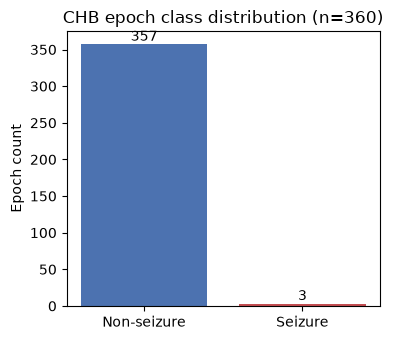

In [4]:
n_pos = int(y.sum())
n_neg = int((y == 0).sum())
prevalence = n_pos / len(y)
always_negative_accuracy = n_neg / len(y)

print(f"Negative: {n_neg}")
print(f"Positive: {n_pos}")
print(f"Positive prevalence ≈ {prevalence:.2%}")
print(f"Always-negative accuracy ≈ {always_negative_accuracy:.2%}")

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.bar(["Non-seizure", "Seizure"], [n_neg, n_pos], color=["#4C72B0", "#C44E52"])
for i, v in enumerate([n_neg, n_pos]):
    ax.text(i, v + 5, str(v), ha="center")
ax.set_ylabel("Epoch count")
ax.set_title("CHB epoch class distribution (n=360)")
fig.tight_layout()
fig.savefig(FIG_DIR / "class_distribution.png", dpi=150)
plt.show()

With positive prevalence at ≈0.83%, an always-negative classifier already reaches ≈99.17%
accuracy while detecting zero seizures. Raw accuracy is therefore essentially useless as a
primary metric here; imbalance-aware metrics (recall, precision, F1, PR-AUC on the positive
class) are used instead throughout this notebook.

## 6. Recording-aware feasibility diagnostic

Before running any exploratory evaluation, we check whether a recording-independent
(leave-one-recording-out) evaluation of seizure generalization is even possible with the
available annotations.

In [5]:
per_recording = df.groupby("recording_id")["y_seizure"].agg(["count", "sum"])
per_recording.columns = ["n_epochs", "n_positive"]
print(per_recording)

print()
for rec in per_recording.index:
    held_out_train_pos = int(per_recording.drop(index=rec)["n_positive"].sum())
    held_out_test_pos = int(per_recording.loc[rec, "n_positive"])
    print(
        f"Holding out {rec}: train positives = {held_out_train_pos}, "
        f"test positives = {held_out_test_pos}"
    )

              n_epochs  n_positive
recording_id                      
chb_s01_r01        120           0
chb_s01_r02        120           0
chb_s01_r03        120           3

Holding out chb_s01_r01: train positives = 3, test positives = 0
Holding out chb_s01_r02: train positives = 3, test positives = 0
Holding out chb_s01_r03: train positives = 0, test positives = 3


**Finding:** every recording is either entirely seizure-negative (`chb_s01_r01`,
`chb_s01_r02`) or contains all 3 positive epochs (`chb_s01_r03`).

- Holding out `chb_s01_r03`: the training set has **zero** positive samples, so Logistic
  Regression cannot learn a seizure-vs-non-seizure decision at all.
- Holding out either other recording: the test set has **zero** positive samples, so seizure
  recall / PR-AUC cannot meaningfully evaluate positive detection.

**A valid leave-one-recording-out estimate of seizure generalization is not estimable from the
available annotations.** This is a property of the current dataset, not a bug — no evaluation
design implemented later in this notebook attempts to work around it. Section 7 instead runs a
clearly-labeled exploratory epoch-level evaluation that does not claim recording independence.

## 7. Exploratory epoch-level cross-validation

**Exploratory epoch-level OOF evaluation.** Because Section 6 shows that no recording-independent
split is possible, this evaluation instead uses `StratifiedKFold(n_splits=3, shuffle=True,
random_state=42)` over individual epochs, which places approximately one positive epoch per fold.

This produces out-of-fold (OOF) predictions for every epoch using a Logistic Regression pipeline
(`StandardScaler` fit per training fold → `LogisticRegression(class_weight="balanced")`), with the
standard decision threshold of 0.5 (not tuned against these 3 positives).

**This evaluation is optimistically biased** and must not be interpreted as independent-event,
cross-recording, or cross-subject generalization: the 3 positive epochs are adjacent segments of
the same seizure event, so a positive epoch in one fold's test set is temporally and physiologically
close to positive epochs used in that fold's training set.

In [6]:
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        solver="lbfgs",
        max_iter=1000,
    )),
])

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

lr_oof_probability = np.zeros(len(X))
fold_id = np.full(len(X), -1)

for i, (train_idx, test_idx) in enumerate(skf.split(X, y)):
    lr_pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])
    lr_oof_probability[test_idx] = lr_pipeline.predict_proba(X.iloc[test_idx])[:, 1]
    fold_id[test_idx] = i
    n_pos_train = int(y.iloc[train_idx].sum())
    n_pos_test = int(y.iloc[test_idx].sum())
    print(f"Fold {i}: train positives = {n_pos_train}, test positives = {n_pos_test}")

lr_oof_prediction = (lr_oof_probability >= 0.5).astype(int)
print()
print("OOF predictions generated for", len(lr_oof_probability), "epochs")

Fold 0: train positives = 2, test positives = 1
Fold 1: train positives = 2, test positives = 1


Fold 2: train positives = 2, test positives = 1

OOF predictions generated for 360 epochs


## 8. Dummy reference

A majority-class (`always-negative`) `DummyClassifier` is used only as a reference point, to show
why raw accuracy is misleading under this imbalance. It is not a competing model in a benchmark.

In [7]:
dummy_clf = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)

dummy_oof_probability = np.zeros(len(X))

for train_idx, test_idx in skf.split(X, y):
    dummy_clf.fit(X.iloc[train_idx], y.iloc[train_idx])
    dummy_oof_probability[test_idx] = dummy_clf.predict_proba(X.iloc[test_idx])[:, 1]

dummy_oof_prediction = (dummy_oof_probability >= 0.5).astype(int)
print("Dummy OOF predicted positives:", int(dummy_oof_prediction.sum()))

Dummy OOF predicted positives: 0


## 9. Metrics

Primary metrics focus on the positive (seizure) class; raw accuracy is reported but de-emphasized.
`zero_division=0` is used to avoid crashes on undefined precision/F1 and any such occurrence is
reported transparently rather than hidden.

In [8]:
def compute_metrics(y_true, y_pred, y_prob, label):
    metrics = {
        "precision_positive": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall_positive": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_positive": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "average_precision": average_precision_score(y_true, y_prob),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
    }
    try:
        metrics["roc_auc"] = roc_auc_score(y_true, y_prob)
    except ValueError as e:
        metrics["roc_auc"] = None
        print(f"[{label}] ROC-AUC not valid: {e}")

    n_pred_pos = int(np.sum(y_pred == 1))
    if n_pred_pos == 0:
        print(f"[{label}] Precision is undefined (0 predicted positives); reported as 0 by convention.")

    return metrics

lr_metrics = compute_metrics(y.values, lr_oof_prediction, lr_oof_probability, "LogisticRegression")
dummy_metrics = compute_metrics(y.values, dummy_oof_prediction, dummy_oof_probability, "Dummy")

print()
print("Logistic Regression (exploratory OOF):")
for k, v in lr_metrics.items():
    print(f"  {k}: {v}")

print()
print("Dummy (always-negative) reference:")
for k, v in dummy_metrics.items():
    print(f"  {k}: {v}")

lr_cm = confusion_matrix(y.values, lr_oof_prediction, labels=[0, 1])
dummy_cm = confusion_matrix(y.values, dummy_oof_prediction, labels=[0, 1])
print()
print("Logistic Regression confusion matrix [rows=true, cols=pred]:")
print(lr_cm)
print("Dummy confusion matrix [rows=true, cols=pred]:")
print(dummy_cm)

[Dummy] Precision is undefined (0 predicted positives); reported as 0 by convention.

Logistic Regression (exploratory OOF):
  precision_positive: 0.09090909090909091
  recall_positive: 0.3333333333333333
  f1_positive: 0.14285714285714285
  average_precision: 0.3489628349178911
  balanced_accuracy: 0.6526610644257703
  accuracy: 0.9666666666666667
  roc_auc: 0.6237161531279178

Dummy (always-negative) reference:
  precision_positive: 0.0
  recall_positive: 0.0
  f1_positive: 0.0
  average_precision: 0.008333333333333333
  balanced_accuracy: 0.5
  accuracy: 0.9916666666666667
  roc_auc: 0.5

Logistic Regression confusion matrix [rows=true, cols=pred]:
[[347  10]
 [  2   1]]
Dummy confusion matrix [rows=true, cols=pred]:
[[357   0]
 [  3   0]]


## 10. Confusion matrix

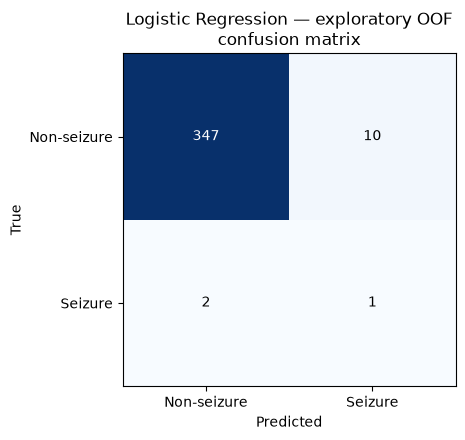

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(lr_cm, cmap="Blues")
labels = ["Non-seizure", "Seizure"]
ax.set_xticks([0, 1]); ax.set_xticklabels(labels)
ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Logistic Regression — exploratory OOF\nconfusion matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(lr_cm[i, j]), ha="center", va="center",
                 color="white" if lr_cm[i, j] > lr_cm.max() / 2 else "black")
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## 11. Precision–Recall curve

PR analysis is preferred over ROC given the extreme class imbalance (357:3).

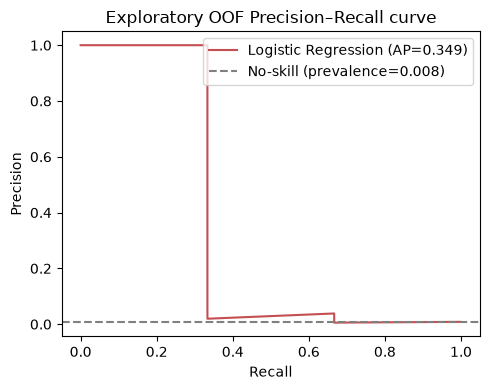

In [10]:
precision_curve, recall_curve, _ = precision_recall_curve(y.values, lr_oof_probability)
ap = lr_metrics["average_precision"]

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(recall_curve, precision_curve, color="#C44E52", label=f"Logistic Regression (AP={ap:.3f})")
ax.axhline(prevalence, color="gray", linestyle="--", label=f"No-skill (prevalence={prevalence:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Exploratory OOF Precision–Recall curve")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "precision_recall_curve.png", dpi=150)
plt.show()

## 12. Temporal probability plot

Reliable epoch timing metadata (`t_center_sec`) exists in the processed artifact for
`chb_s01_r03`, so it is used directly (no timing is invented). The plot shows the exploratory OOF
predicted probability per epoch against time, with the verified annotated seizure interval
(2996–3036 s) marked.

**This model detects whether the current epoch intersects a seizure annotation. It does not
predict seizure onset ahead of time — this is not seizure forecasting.**

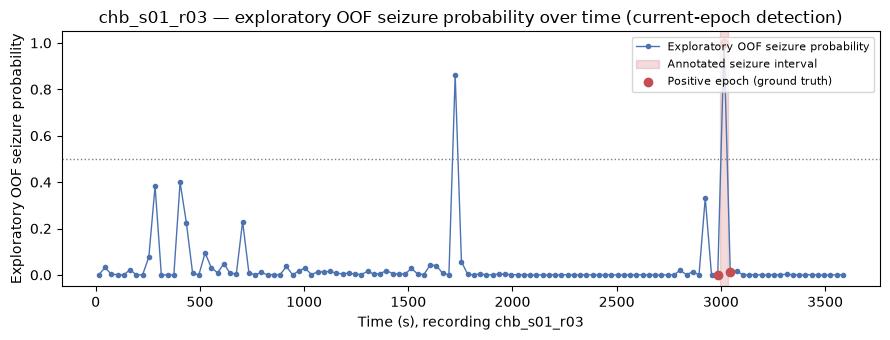

In [11]:
mask_r03 = (df["recording_id"] == "chb_s01_r03").values
t = df.loc[mask_r03, "t_center_sec"].values
prob_r03 = lr_oof_probability[mask_r03]
y_r03 = y.values[mask_r03]

order = np.argsort(t)
t, prob_r03, y_r03 = t[order], prob_r03[order], y_r03[order]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t, prob_r03, color="#4C72B0", marker="o", markersize=3, linewidth=1,
        label="Exploratory OOF seizure probability")
ax.axvspan(2996, 3036, color="#C44E52", alpha=0.2, label="Annotated seizure interval")
ax.scatter(t[y_r03 == 1], prob_r03[y_r03 == 1], color="#C44E52", zorder=5, label="Positive epoch (ground truth)")
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)
ax.set_xlabel("Time (s), recording chb_s01_r03")
ax.set_ylabel("Exploratory OOF seizure probability")
ax.set_title("chb_s01_r03 — exploratory OOF seizure probability over time (current-epoch detection)")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "seizure_probability_chb01_03.png", dpi=150)
plt.show()

## 13. Fit final baseline model on all CHB data

A final Logistic Regression pipeline is fit on all 360 rows to preserve a baseline model
artifact and inspect coefficients. **Its training performance is not reported as a generalization
estimate** — that role belongs to Section 7's exploratory OOF evaluation.

In [12]:
final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        solver="lbfgs",
        max_iter=1000,
    )),
])
final_pipeline.fit(X, y)

model_path = OUT_DIR / "logistic_regression_baseline.joblib"
joblib.dump(final_pipeline, model_path)
print("Saved final baseline model to:", model_path)

Saved final baseline model to: /home/evgenija/projects/EEG_timeseries_project/outputs/modeling/baseline/logistic_regression_baseline.joblib


## 14. Feature coefficient interpretation

Coefficients are taken from the final model's Logistic Regression fit on standardized features,
so magnitude is comparable across features. These describe features most strongly associated with
the classifier's decision in this small exploratory baseline — they are **not** evidence of
neurological causes of seizures; correlation/model coefficient is not causation.

          feature  coefficient  abs_coefficient
        rel_alpha     2.547654         2.547654
theta_alpha_ratio     1.813641         1.813641
            alpha     1.180989         1.180989
         rel_beta    -1.132849         1.132849
          entropy     0.869845         0.869845
        rel_theta    -0.741772         0.741772
              var     0.519360         0.519360
            delta     0.518542         0.518542
             beta    -0.426955         0.426955
 delta_beta_ratio    -0.398984         0.398984


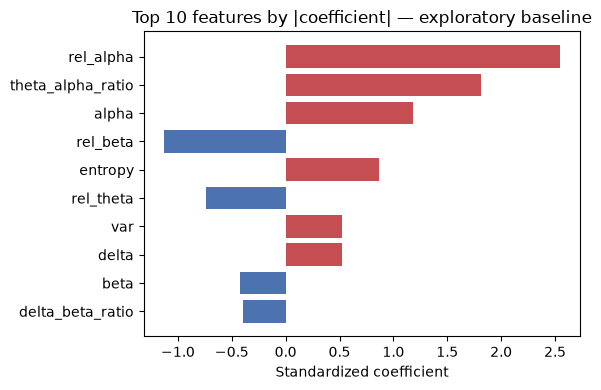

In [13]:
coefs = final_pipeline.named_steps["clf"].coef_.ravel()
coef_df = pd.DataFrame({
    "feature": feature_cols,
    "coefficient": coefs,
    "abs_coefficient": np.abs(coefs),
}).sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

coef_path = OUT_DIR / "baseline_coefficients.csv"
coef_df.to_csv(coef_path, index=False)

print(coef_df.head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
top10 = coef_df.head(10).iloc[::-1]
colors = ["#C44E52" if c > 0 else "#4C72B0" for c in top10["coefficient"]]
ax.barh(top10["feature"], top10["coefficient"], color=colors)
ax.set_xlabel("Standardized coefficient")
ax.set_title("Top 10 features by |coefficient| — exploratory baseline")
fig.tight_layout()
fig.savefig(FIG_DIR / "feature_coefficients.png", dpi=150)
plt.show()

## 15. Save reproducible outputs

In [14]:
# OOF predictions for every epoch
oof_df = df[["recording_id", "epoch_idx", "t_start_sec", "t_end_sec", "y_seizure"]].copy()
oof_df["lr_oof_probability"] = lr_oof_probability
oof_df["lr_oof_prediction"] = lr_oof_prediction
oof_df["dummy_oof_probability"] = dummy_oof_probability
oof_df["dummy_oof_prediction"] = dummy_oof_prediction
oof_df["cv_fold"] = fold_id

oof_path = OUT_DIR / "baseline_oof_predictions.csv"
oof_df.to_csv(oof_path, index=False)

# Metrics (LR + dummy), JSON-safe
def to_jsonable(d):
    return {k: (float(v) if v is not None else None) for k, v in d.items()}

metrics_out = {
    "logistic_regression": to_jsonable(lr_metrics),
    "dummy_always_negative": to_jsonable(dummy_metrics),
    "logistic_regression_confusion_matrix": lr_cm.tolist(),
    "dummy_confusion_matrix": dummy_cm.tolist(),
    "always_negative_accuracy": float(always_negative_accuracy),
}
metrics_path = OUT_DIR / "baseline_metrics.json"
with open(metrics_path, "w") as f:
    json.dump(metrics_out, f, indent=2)

# Metadata
metadata_out = {
    "task": "binary current-epoch seizure detection",
    "model": "LogisticRegression",
    "random_state": RANDOM_STATE,
    "n_features": len(feature_cols),
    "feature_names": feature_cols,
    "positive_epochs": n_pos,
    "negative_epochs": n_neg,
    "positive_prevalence": prevalence,
    "evaluation": "exploratory 3-fold stratified epoch-level OOF",
    "decision_threshold": 0.5,
    "independent_event_generalization": "NOT ESTIMABLE",
    "reason": "all positive epochs originate from one seizure event in chb_s01_r03; "
              "leave-one-recording-out is infeasible (Section 6)",
    "source_features_file": str(FEATURES_PATH),
}
metadata_path = OUT_DIR / "baseline_metadata.json"
with open(metadata_path, "w") as f:
    json.dump(metadata_out, f, indent=2)

print("Saved:")
for p in [oof_path, metrics_path, metadata_path, coef_path, model_path]:
    print(" -", p, "exists:", p.exists())

Saved:
 - /home/evgenija/projects/EEG_timeseries_project/outputs/modeling/baseline/baseline_oof_predictions.csv exists: True
 - /home/evgenija/projects/EEG_timeseries_project/outputs/modeling/baseline/baseline_metrics.json exists: True
 - /home/evgenija/projects/EEG_timeseries_project/outputs/modeling/baseline/baseline_metadata.json exists: True
 - /home/evgenija/projects/EEG_timeseries_project/outputs/modeling/baseline/baseline_coefficients.csv exists: True
 - /home/evgenija/projects/EEG_timeseries_project/outputs/modeling/baseline/logistic_regression_baseline.joblib exists: True


## 16. Final notebook conclusion

In [15]:
from IPython.display import display, Markdown

conclusion = f"""
### A. Did the baseline find evidence of feature separability?

The exploratory 3-fold stratified OOF evaluation gives:

- Precision (seizure class): **{lr_metrics['precision_positive']:.3f}**
- Recall (seizure class): **{lr_metrics['recall_positive']:.3f}**
- F1 (seizure class): **{lr_metrics['f1_positive']:.3f}**
- Average Precision / PR-AUC: **{lr_metrics['average_precision']:.3f}**
- ROC-AUC: **{lr_metrics['roc_auc']:.3f}**
- Balanced accuracy: **{lr_metrics['balanced_accuracy']:.3f}**
- Raw accuracy (de-emphasized): **{lr_metrics['accuracy']:.3f}**

### B. Comparison with the always-negative dummy baseline

- Dummy accuracy: **{dummy_metrics['accuracy']:.3f}** (≈ always-negative rate {always_negative_accuracy:.3f}) vs.
  Logistic Regression accuracy **{lr_metrics['accuracy']:.3f}** — accuracy alone is uninformative here.
- Dummy seizure recall/F1/PR-AUC are **{dummy_metrics['recall_positive']:.3f} / {dummy_metrics['f1_positive']:.3f} / {dummy_metrics['average_precision']:.3f}**
  by construction (it never predicts a seizure), while Logistic Regression's positive-class recall/F1/PR-AUC
  ({lr_metrics['recall_positive']:.3f} / {lr_metrics['f1_positive']:.3f} / {lr_metrics['average_precision']:.3f})
  show whether the engineered features carry detectable signal beyond the trivial baseline.

### C. What can we legitimately conclude?

This baseline is sufficient as an exploratory feature-signal sanity check, but the dataset
contains only one annotated seizure event. Therefore its scores cannot establish
recording-independent, subject-independent, or event-independent generalization. Section 6's
diagnostic shows this is not a fixable evaluation-design problem given current annotations —
it is a structural property of the available data.

### D. What comes next?

The baseline performs current-epoch binary seizure detection. The next modeling stage should
introduce temporal structure and investigate whether state-change / seizure-transition information
can be modeled prospectively, rather than merely identifying epochs already overlapping a seizure
annotation.
"""

display(Markdown(conclusion))


### A. Did the baseline find evidence of feature separability?

The exploratory 3-fold stratified OOF evaluation gives:

- Precision (seizure class): **0.091**
- Recall (seizure class): **0.333**
- F1 (seizure class): **0.143**
- Average Precision / PR-AUC: **0.349**
- ROC-AUC: **0.624**
- Balanced accuracy: **0.653**
- Raw accuracy (de-emphasized): **0.967**

### B. Comparison with the always-negative dummy baseline

- Dummy accuracy: **0.992** (≈ always-negative rate 0.992) vs.
  Logistic Regression accuracy **0.967** — accuracy alone is uninformative here.
- Dummy seizure recall/F1/PR-AUC are **0.000 / 0.000 / 0.008**
  by construction (it never predicts a seizure), while Logistic Regression's positive-class recall/F1/PR-AUC
  (0.333 / 0.143 / 0.349)
  show whether the engineered features carry detectable signal beyond the trivial baseline.

### C. What can we legitimately conclude?

This baseline is sufficient as an exploratory feature-signal sanity check, but the dataset
contains only one annotated seizure event. Therefore its scores cannot establish
recording-independent, subject-independent, or event-independent generalization. Section 6's
diagnostic shows this is not a fixable evaluation-design problem given current annotations —
it is a structural property of the available data.

### D. What comes next?

The baseline performs current-epoch binary seizure detection. The next modeling stage should
introduce temporal structure and investigate whether state-change / seizure-transition information
can be modeled prospectively, rather than merely identifying epochs already overlapping a seizure
annotation.
